# mem pipeline demo: from a walkthrough video to a humanoid acting on a part
**mem branch** · one real scene (SceneFun3D 421069, video 42444490) · 10 Nov 2026 · a walk-through for discussion, before any training

- **What it shows:** every step of the planned pipeline on one scene, running the same code the experiments will use.
- **Real today:** the inputs (RGB, simple depth, device poses), the memory entries computed from them, the humanoid placement, and every score.
- **Placeholder today (marked ORACLE):** where a part is in the image, its action type, how it moves, and which part a query means. These come from SceneFun3D annotations now; training replaces them later.

```text
(1) video frames + simple depth + device pose                       inputs only, no reconstruction
        ↓
(2) per-frame part masks, action type, part motion                  ORACLE labels now → predicted after training
        ↓
(3) memory: one entry per functional part
    contact point · surface normal · motion · stand point · evidence keyframes
        ↓
(4) query in words → entry + evidence keyframe                      ORACLE match now → feature search later
        ↓
(5) humanoid walks up, faces the part, reaches, acts                 kinematic, SMPL-X
        ↓
(6) scores against the laser scan                                   ground truth, never an input
```

<sub>To re-run: download the scene (`python scripts/download_scenefun3d.py --visit 421069 --video 42444490`, then the same command with `--assets lowres_depth lowres_wide_intrinsics confidence lowres_poses transform motions`), put the SMPL-X model in `data/body_models/smplx/` (registration at smpl-x.is.tue.mpg.de, non-commercial licence, not redistributed here), then Run All. The monocular depth model downloads on first use (1.3 GB).</sub>

In [1]:
import contextlib
import io
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import plotly.io as pio
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
_saved_fd, _null = os.dup(1), os.open(os.devnull, os.O_WRONLY)
os.dup2(_null, 1)  # silence Open3D's import banner (printed from C++)
try:
    with contextlib.redirect_stdout(io.StringIO()):
        import open3d  # noqa: F401
finally:
    os.dup2(_saved_fd, 1)
sys.path.insert(0, str(ROOT))
from affordance3d.mem import pipeline as P
from affordance3d.mem.body import load_smplx
from report.mem_demo_helpers import (entries_figure, entries_table, humanoid_figure, inputs_figure, labels_figure,
                                     make_shots, memory_3d_figure, pick_keyframes, render_approach_video,
                                     retrieval_figure, scaled_mono_depths, scan_view, scoreboard, shots_table)

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
DATA, VISIT, VIDEO = ROOT / "data" / "scenefun3d", "421069", "42444490"
ASSETS = ROOT / "report" / "assets"
MONO_ID = "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf"
MONO_CACHE = ROOT / "runs" / "mem_s1" / "mono" / "DA-V2_L"
N_KEYFRAMES = 40

## 1 · Inputs: what the memory is allowed to see
> **This step:** pick keyframes evenly in time and give each one a depth map and a camera pose from the device.
> **Status:** real. The laser scan, the depth rendered from it and the scan-registered poses are kept apart as ground truth.

The video is an iPad walkthrough (10 FPS RGB). Depth is a monocular estimate rescaled per frame by the iPad's own LiDAR; the pose is ARKit's. No mesh, no global fusion: 3D only ever comes from one frame's depth and pose.

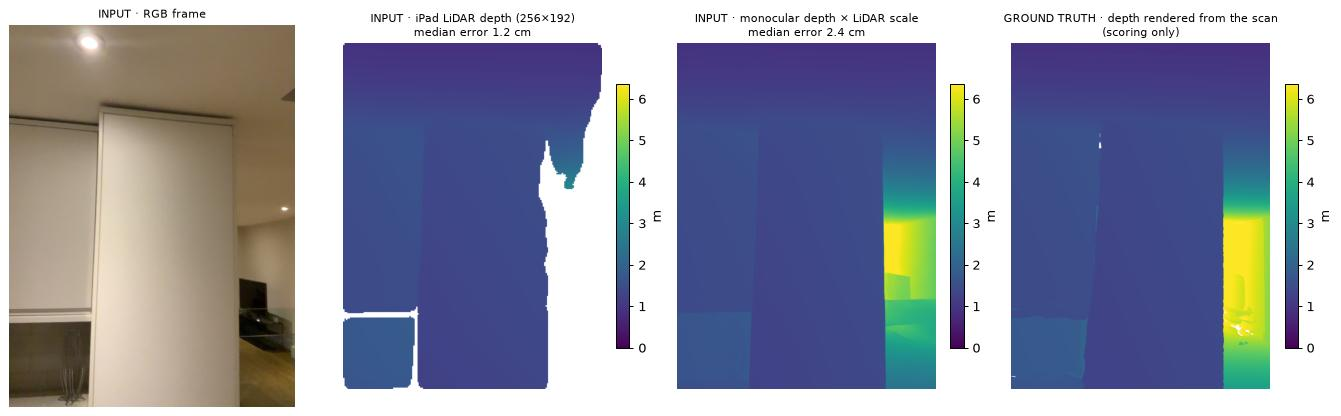

,role,what,detail
0,input,RGB video,1025 frames at 10 FPS; 40 keyframes used
1,input,depth,Depth Anything V2 (monocular) × per-frame LiDA...
2,input,camera pose,"ARKit, from the device"
3,ground truth,laser scan + annotations,"38 functional parts, 37 with a motion, 24 task..."
4,ground truth,"rendered depth, scan-registered poses","used to make labels and to score, never fed to..."


In [2]:
scene = P.load_scene(DATA, VISIT, VIDEO)
keyframes = pick_keyframes(scene, N_KEYFRAMES)
mono = scaled_mono_depths(scene, keyframes, MONO_ID, MONO_CACHE)
gt = P.gt_frames(scene, keyframes)  # ground-truth cameras: labels and scoring only
frames = [P.input_frame(scene, t, d) for t, d in zip(keyframes, mono)]

inputs_figure(scene, keyframes[18], mono[18], gt[18])
plt.show()
pd.DataFrame([
    ("input", "RGB video", f"{len(scene.vid.rgb_times)} frames at 10 FPS; {len(keyframes)} keyframes used"),
    ("input", "depth", "Depth Anything V2 (monocular) × per-frame LiDAR scale; LiDAR alone as a comparison"),
    ("input", "camera pose", "ARKit, from the device"),
    ("ground truth", "laser scan + annotations", f"{len(scene.elements)} functional parts, {len(scene.motions)} with a motion, {len(scene.tasks)} task descriptions"),
    ("ground truth", "rendered depth, scan-registered poses", "used to make labels and to score, never fed to the memory"),
], columns=["role", "what", "detail"])

## 2 · Per-frame labels: part, action type, motion
> **This step:** mark each functional part in the keyframes, with its action type (colour) and how it moves (arrow).
> **Status:** ORACLE. The scan annotations are projected into the frames with the ground-truth camera. After training, a model predicts these three things from the frame; the projections below become its training targets.

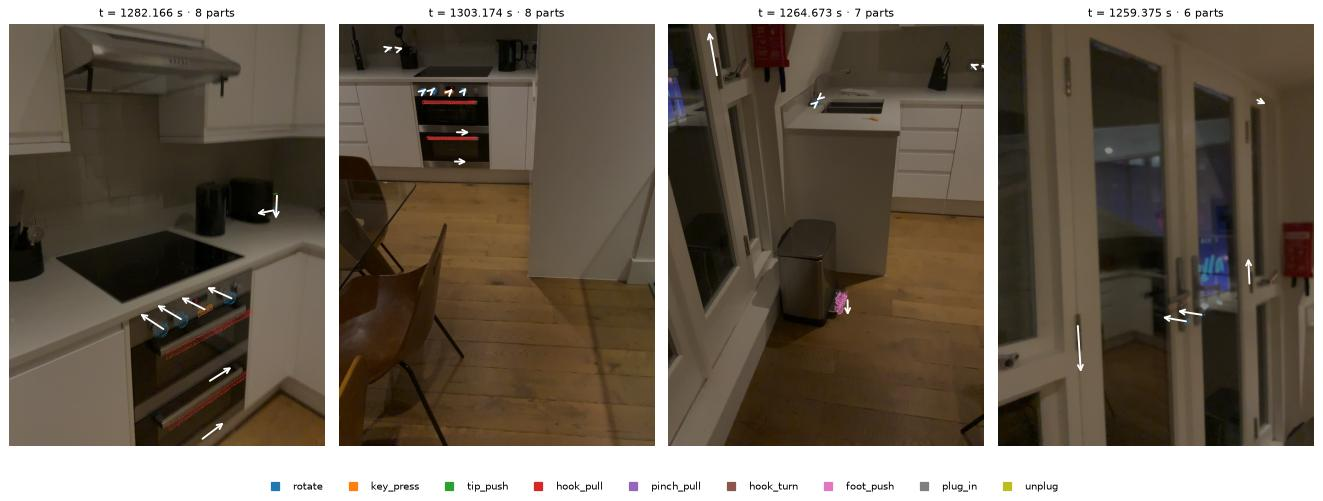

In [3]:
labels = P.label_maps(scene, gt)
labels_figure(scene, gt, labels, keyframes)
plt.show()

## 3 · Memory: one entry per functional part
> **This step:** for each part, take the keyframe where it is largest, lift its contact point with the input depth, fit the surface around it, and plan where a person stands to use it.
> **Status:** geometry is real (inputs only). Which pixels are the part, the action type and the motion are still the labels from step 2.

An entry is what later steps read: **where to touch** (red), **which way the surface faces** (cyan), **how the part moves** (yellow), **where to stand** (ring), and **which keyframes are the evidence**.

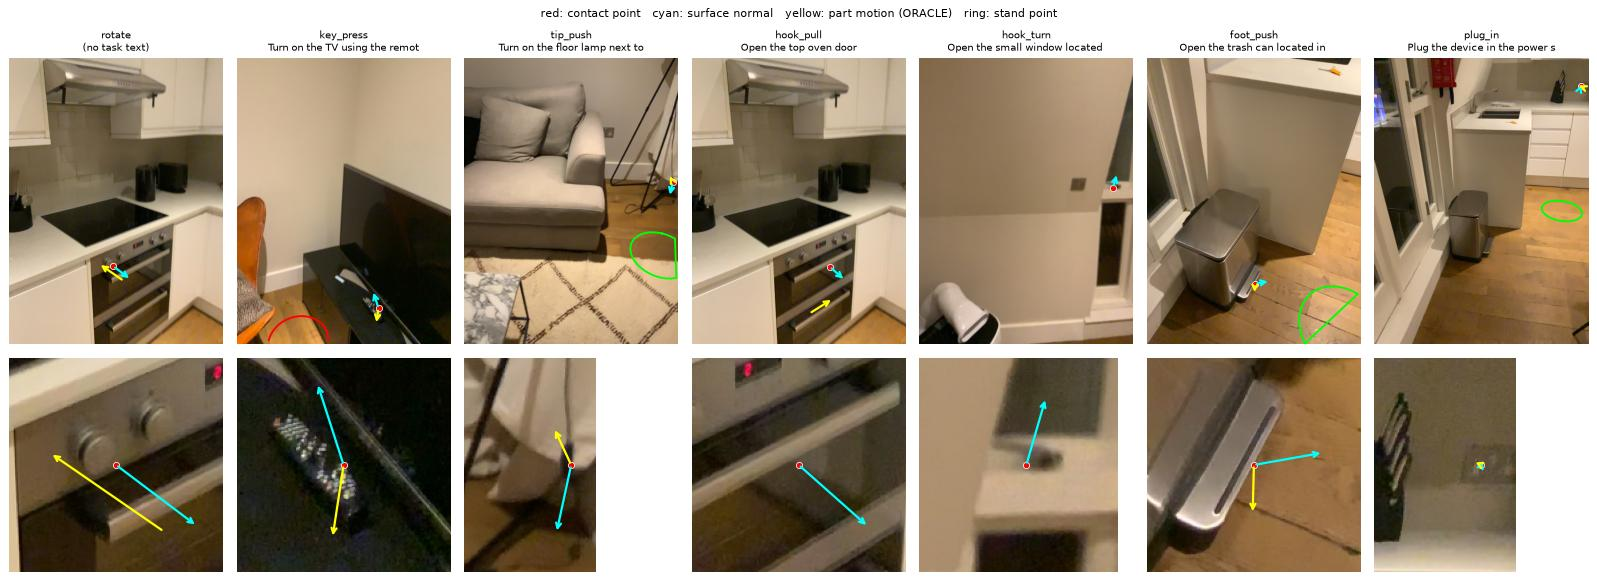

29 of 38 parts have an entry (the others were seen in fewer than 10 pixels)


,action,"task (the effect, from SceneFun3D)",best keyframe,seen in,motion,contact error,stand point
0,foot_push,Open the trash can located in the kitchen near...,1267.272 s,4 keyframes,slides,0.3 cm,free
1,hook_pull,Open the bottom oven door,1282.166 s,3 keyframes,rotates,9.0 cm,free
2,hook_pull,Open the glass door next to the black floor lamp,1326.381 s,1 keyframes,rotates,6.5 cm,free
3,hook_turn,Open the left balcony door located in the kitchen,1259.375 s,2 keyframes,rotates,12.0 cm,free
4,hook_turn,Open the right balcony door located in the kit...,1259.375 s,4 keyframes,rotates,14.5 cm,free
5,key_press,Turn on the TV using the remote control locate...,1321.167 s,4 keyframes,slides,5.4 cm,blocked in scan
6,key_press,–,1282.166 s,3 keyframes,slides,3.8 cm,free
7,plug_in,Plug the device in one of the sockets behind t...,1249.279 s,3 keyframes,slides,4.1 cm,free
8,plug_in,Plug the device in the power supply located ne...,1264.673 s,2 keyframes,slides,11.3 cm,free
9,rotate,Increase the toaster's intensity,1282.166 s,1 keyframes,rotates,42.8 cm,free


In [4]:
memory = P.build_memory(scene, keyframes, frames, labels)
view = scan_view(scene)  # ground-truth scan, for scoring and display
by_time, labels_by_time = dict(zip(keyframes, frames)), dict(zip(keyframes, labels))

entries_figure(scene, memory, by_time, view)
plt.show()
print(f"{len(memory.entries)} of {len(scene.elements)} parts have an entry (the others were seen in fewer than {P.MIN_PART_PIXELS} pixels)")
entries_table(scene, memory, view).groupby("action").head(2).reset_index(drop=True)

### The memory in 3D (drag to rotate; hover a marker for its task). The scan is only the backdrop.

In [5]:
memory_3d_figure(scene, memory, view)

## 4 · Query → entry → evidence
> **This step:** a task in words returns the part to act on, how to act, and the keyframe that proves it was seen.
> **Status:** ORACLE match. The query must be one of SceneFun3D's task descriptions, and the task → part link is the annotated one. The planned replacement is a feature search over the memory.

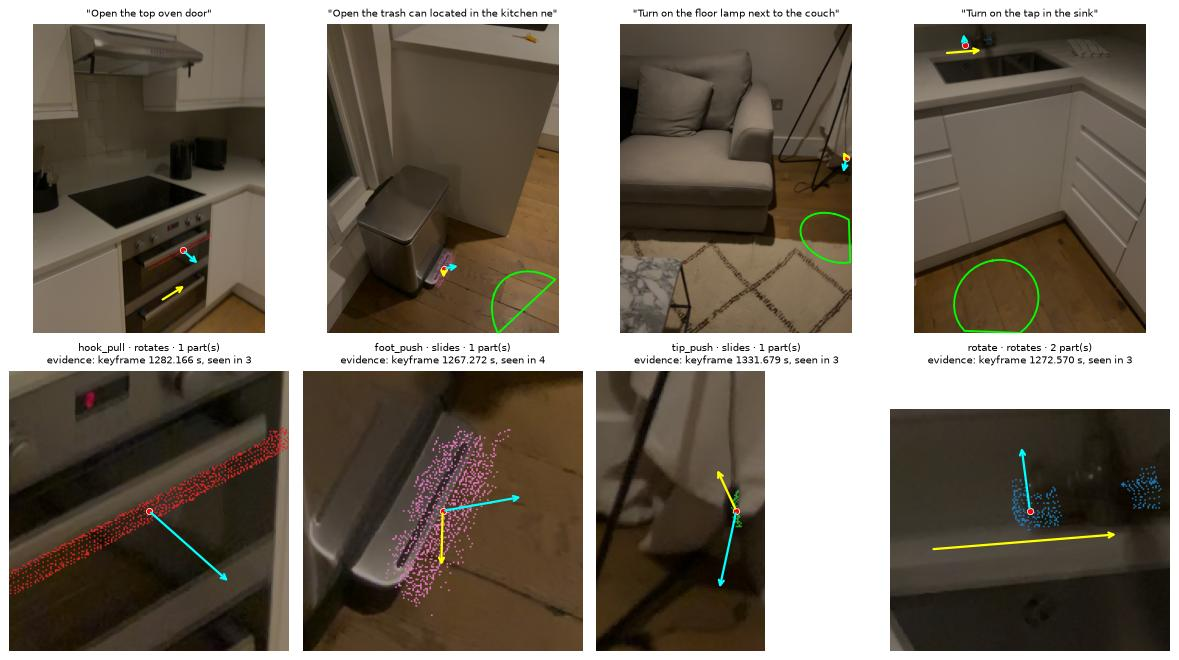

In [6]:
QUERIES = ["Open the top oven door", "Open the trash can located in the kitchen near the sink",
           "Turn on the floor lamp next to the couch", "Turn on the tap in the sink"]
retrieval_figure(scene, memory, QUERIES, by_time, labels_by_time, view)
plt.show()

## 5 · Humanoid: walk up, reach, act
> **This step:** the entry drives an SMPL-X body: stand at the stand point, face the part, squat if it is low, bring the hand (or foot) to the contact point. The display frame is searched over the whole video for the view that shows both the part and the person.
> **Status:** real given the entry. Kinematic only: no physics, no finger motion, a simple walk cycle.

Left: pasted into the real video frame, hidden behind furniture using the input depth. Right: the same body inside the laser scan, where magenta marks the true part.

In [7]:
body = load_smplx(ROOT / "data" / "body_models" / "smplx" / "SMPLX_NEUTRAL.npz")
shots = make_shots(scene, memory, body, QUERIES, MONO_ID, MONO_CACHE)
CLIP = ASSETS / "mem_approach_demo.mp4"
render_approach_video(scene, memory, body, shots, view, CLIP)
Video(str(CLIP), embed=True, width=960)

### Final pose of each query (still images of the clip above)

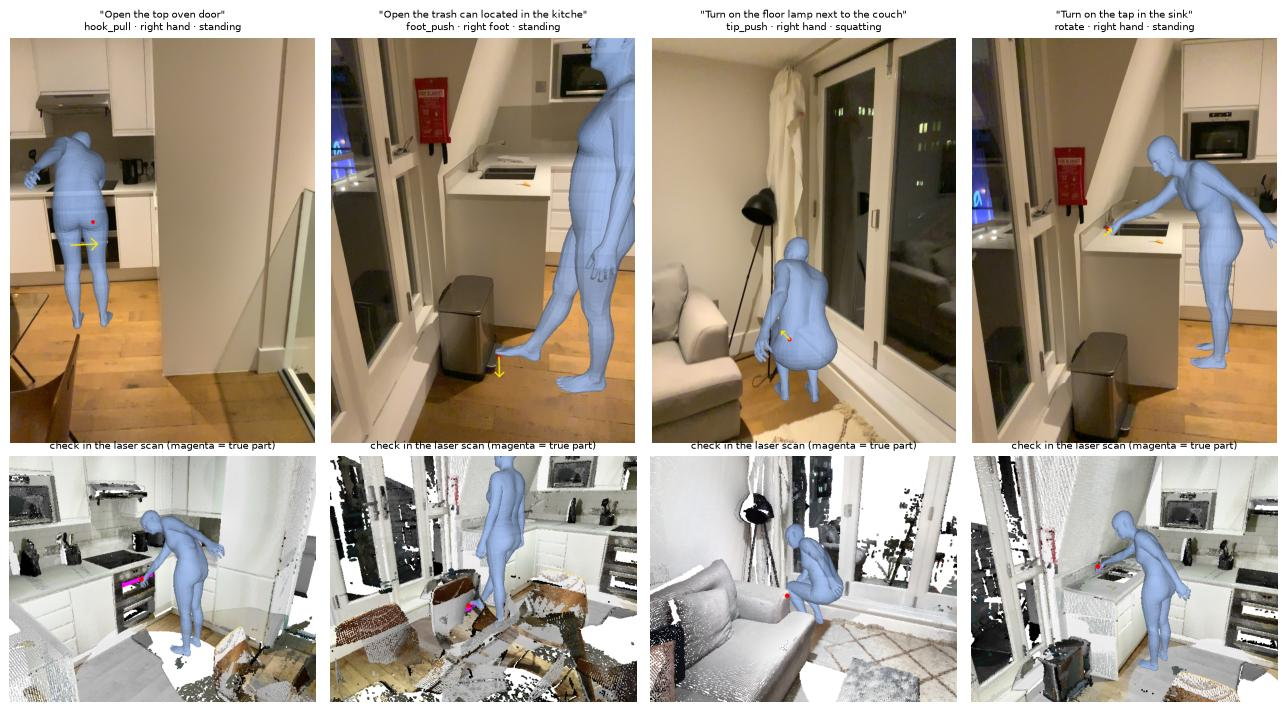

,query,acts with,hand/foot to true part,feet above true floor,body inside scan geometry
0,Open the top oven door,"right hand, standing",1.6 cm,+4.5 cm,0.0%
1,Open the trash can located in the kitchen near...,"right foot, standing",5.9 cm,+5.5 cm,0.0%
2,Turn on the floor lamp next to the couch,"right hand, squatting",8.6 cm,+2.3 cm,0.0%
3,Turn on the tap in the sink,"right hand, standing",6.8 cm,+4.9 cm,0.1%


In [8]:
humanoid_figure(scene, shots, body, view)
plt.show()
shots_table(scene, shots, view)

## 6 · Scores against the laser scan
> **This step:** how close the memory's contact points are to the true parts, and whether the planned stand points are really free.
> **Status:** real, but one scene and one video: these numbers show where the error comes from, they are not results.

In [9]:
lidar_frames = [P.input_frame(scene, t, P.lidar_depth(scene, t)) for t in keyframes]
scoreboard(scene, {"monocular × LiDAR scale (used above)": memory,
                   "iPad LiDAR only": P.build_memory(scene, keyframes, lidar_frames, labels)}, view)

,parts in memory,contact error (median),contact on the part (≤ 3 cm),stand point free in the scan
depth used to build the memory,,,,
monocular × LiDAR scale (used above),29 of 38,7.7 cm,14%,93%
iPad LiDAR only,24 of 38,2.8 cm,54%,75%


**What this run shows**
- With perfect knowledge of *which pixels* are the part, the remaining error is depth and pose: the contact point is off by a median of 7.7 cm with monocular depth and 2.8 cm with LiDAR. Parts are only a few cm wide, so depth at the part is the bottleneck for "position accurate".
- LiDAR is more accurate but has holes: it gives an entry for 24 parts, monocular depth for 29.
- The humanoid lands its hand or foot 2–9 cm from the true part in these four cases, with feet 2–6 cm above the true floor (ARKit height drift).

**What training changes**

| step | today | after training |
|---|---|---|
| 2 · part mask, action type, motion | projected annotations (ORACLE) | predicted per frame from RGB (+ depth) |
| 3 · memory entry | geometry from inputs, labels from step 2 | same geometry, predicted labels; evidence merged over keyframes |
| 4 · query → entry | annotated task → part link (ORACLE) | search over memory features |
| 5 · humanoid | simple walk cycle + IK | generated approach motion (LINGO / DartControl on the A6000 server) |

**To decide together**
1. Depth at small parts: prefer LiDAR near the part, fit the surrounding surface, or make the contact depth a prediction target?
2. The stand-point check treats unobserved space as free; it should only allow space that was observed to be free.
3. Which queries should step 4 support first: SceneFun3D task sentences only, or free text?
4. Is this the right picture for the humanoid (pose, view, level of detail), before investing in generated motion?